In [1]:
from auxillaryFunctions import *
from scipy.signal import welch

np.random.seed(0)

#build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
# moduleDir = os.path.join(build_dir, configType)
moduleDir = "build"
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, 
                   recordingKeys = ["voltages","calciumVals","netCurrent","current"],singleThread=False):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    if singleThread:
        cathalTest.solveNeuralSystemSingleThread(ac,recordingData,TS,nIterations,samplingInterval)
    else:
        cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)
    
    #trackPerfOverTime(ac)
    recordingData["time"] = tv
    return recordingData

def getCorrectSpikerOutput(data):
    #"spikes" as recorded can last for more than one iteration because its just Vm>0 
    deriv = np.diff(data["spikerOutput"],axis=0)>0
    deriv = np.pad(deriv, ((1, 0), (0, 0)), mode='constant')
    return deriv

def getPopSpikeTrains(simData,data):
    correctOp = getCorrectSpikerOutput(data)

    spikeTimes = [[] for i in range(data["spikerOutput"].shape[1])]
    for timeInd,neurInd in zip(*np.where(correctOp)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    indices = {}
    for popName,popDict in  simData["indexMaps"]["neuronPopToSpikerMap"].items():
        indices[popName] = list(popDict.values())

    spikeTimeDict = {}
    for pop,inds in indices.items():
        spikeTimeDict[pop] = [spikeTimes[i] for i in inds]

    return spikeTimeDict


Total number of channels 4320
Elapsed time in seconds: 0.6047711
STN 10.75
GPe 29.833333333333332
CTX 3.6625
MSN 1.975


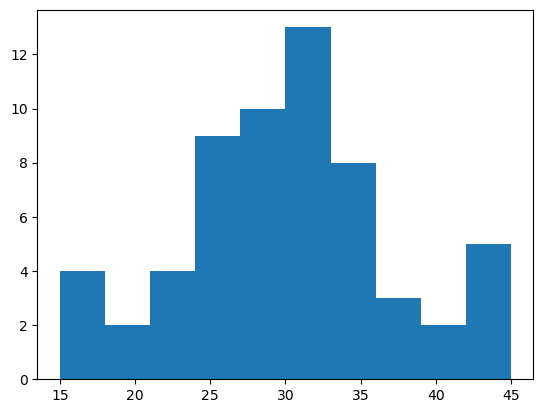

In [21]:
np.random.seed(0)

STNchannels = np.load(os.path.join(r"tools","translatedSTNchannels2.npy"),allow_pickle=True).item()
GPechannels = np.load(os.path.join(r"tools","translatedGPechannels2.npy"),allow_pickle=True).item()
STNbias = -2.05
GPeBias = -0.55

TS = 0.04
runTime = 400

simScale = 20
k = 10
nSTN,nGPe = simScale,3*simScale
nCTX,nMSN = 10*simScale, 30*simScale
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


bestRes = [0.06,0.025,0.01,0.005,0.27115]
wCTXToSTN =  bestRes[0] 
wSTNToGPe = bestRes[1]
wGPeToSTN = bestRes[2]
wGPeToGPe = bestRes[3]
wMSNToGPe =  bestRes[4]

parameters = {
    "simScale":simScale, "k":k,
    "nSTN":nSTN, "nGPe":nGPe,
    "nCTX":nCTX, "nMSN":nMSN,
    "CTXrate":CTXrate, "MSNrate":MSNrate,
    "nSTN_GPe":nSTN_GPe,"nGPe_GPe":nGPe_GPe,"nGPe_STN":nGPe_STN,
    "nCTX_STN":nCTX_STN,"nMSN_GPe":nMSN_GPe,
    "wSTNToGPe":wSTNToGPe, "wGPeToSTN":wGPeToSTN, "wGPeToGPe":wGPeToGPe,
    "wMSNToGPe":wMSNToGPe, "wCTXToSTN":wCTXToSTN
}


coupling,nSegments = 0.25,2 #2 segments gives 3 total segments including soma
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]

GPeDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
GPeDendriteInfo = [{"channels":GPechannels,"bias":GPeBias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias,denderiteInfo=GPeDendriteInfo,dendriteMap=GPeDendriteMap) for i in range(nGPe)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}



CSplasticityParameters = {
        "efficacy": 0, #p, unitless
        "conductanceGain": 0, #
        "rate": 0*3.3e-5, #ms
        "gammaP": 0.1, #p per ms above thetaP 
        "gammaD": 0.01, #p per ms abover thetaD
        "thetaP": 0.75e-5, #Ca mol/L
        "thetaD": 0.55e-5, #Ca mol/L
    }

CSexcSynapses = {"AMPA":genAMPA(TS,wCTXToSTN,**CSplasticityParameters),
                        "NMDA_ion":genNMDA_ion(TS,wCTXToSTN,conductanceGain=0),
                        "NMDA_Ca":genNMDA_Ca(TS,wCTXToSTN,conductanceGain=0)}


CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,wCTXToSTN,0.2,TS,synapses=CSexcSynapses)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,wSTNToGPe,2,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,wGPeToSTN,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,wGPeToGPe,1,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nMSN_GPe,wMSNToGPe,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

stimInfoSpikes,stimInfoCurrents = {},{}
simDataCpp = deepcopy(simData)
simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                        recordingKeys =["spikerOutput","voltages","calciumVals","efficacy"],singleThread=False)


spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)

firingRates = {}
for pop,data in spikeTimeDict.items():
    firingRates[pop] = (1e3/runTime)* np.array([len(x) for x in data])

plt.hist(firingRates["GPe"]);
for pop,rates in firingRates.items():
    print(pop,np.mean(rates))

In [22]:
# V = dataCpp["voltages"]
# Ca = dataCpp["calciumVals"]
# p = dataCpp["efficacy"]
# tv = dataCpp["time"]
# fig,ax = plt.subplots(3,1,figsize=(14,6),sharex=True,dpi=120)
# ax[0].plot(tv,V,label = simData["neuronName"])
# ax[0].set_title("Voltage")
# ax[0].set_ylabel("Vm (mV)")
# ax[1].plot(tv,Ca,label = simData["neuronName"])
# ax[1].set_title("Calcium conc.")
# ax[1].set_ylabel("Ca (mol/L)")
# ax[2].plot(tv,p[:,-4::],label = simData["channelName"][-4::]);
# for a in ax:
#     a.legend()  

# # if the rate is 0 why are these ampar synapses getting stronger

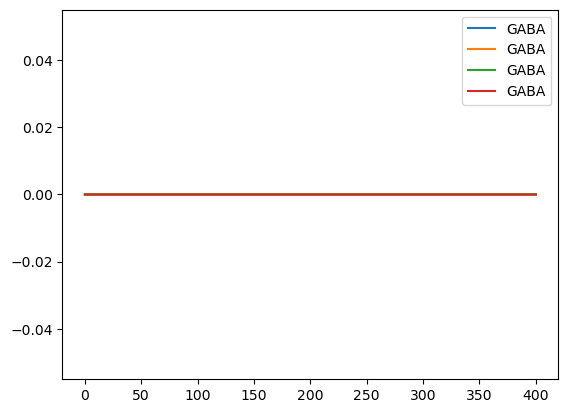

In [29]:
V = dataCpp["voltages"]
Ca = dataCpp["calciumVals"]
p = dataCpp["efficacy"]
tv = dataCpp["time"]
plt.plot(tv,p[:,-4::],label = simData["channelName"][-4::]);
plt.legend()

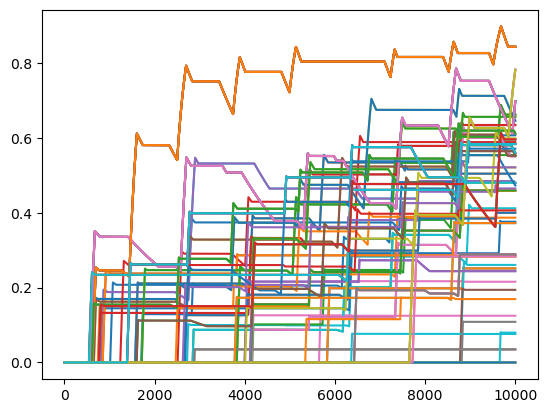

In [40]:
inds = np.where(np.array(simData["channelName"]) == 'AMPAR')[0]
plt.plot(p[:,inds[0:100]]);

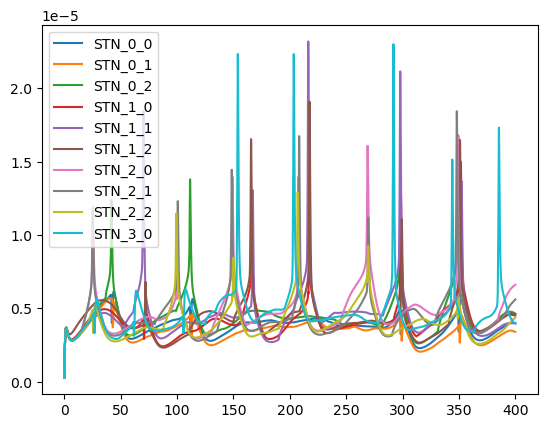

In [32]:
plt.plot(tv,Ca[:,0:10],label = simData["neuronName"][0:10]);
plt.legend()

In [4]:
#TODO: fit the full segment model
#From the rasters it looks like we only have 10 GPe neurons and 30 STN, the opposite of what it should be
#Are the names being set incorrectly? is it to do with the stn dendrites?
#Current theory is that all segments are being used to generate a spike 
#I think it relates to the spikerPreNeuron variable. 
#TODO: We need to create a much simpler test system for this
#TODO: Get segments working in GPe too

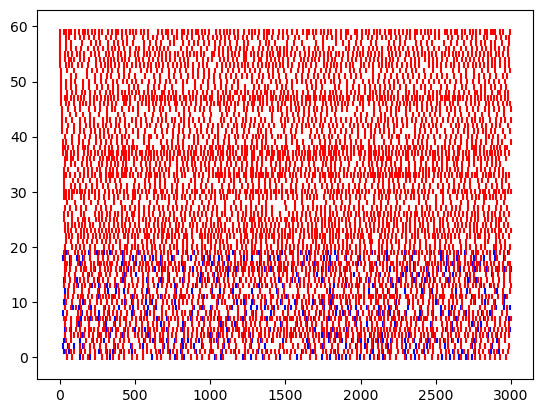

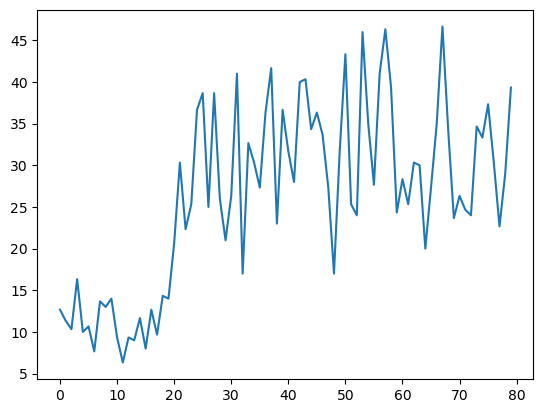

In [13]:
spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)
fig,ax = plt.subplots(1,1)
ax.eventplot(spikeTimeDict["STN"],color="b");
ax.eventplot(spikeTimeDict["GPe"],color="r");

plt.figure()
correctOp = getCorrectSpikerOutput(dataCpp)
#plt.plot(correctOp[:,0:1])
plt.plot((1000/TS)*np.mean(correctOp,axis=0)[0:nSTN+nGPe])

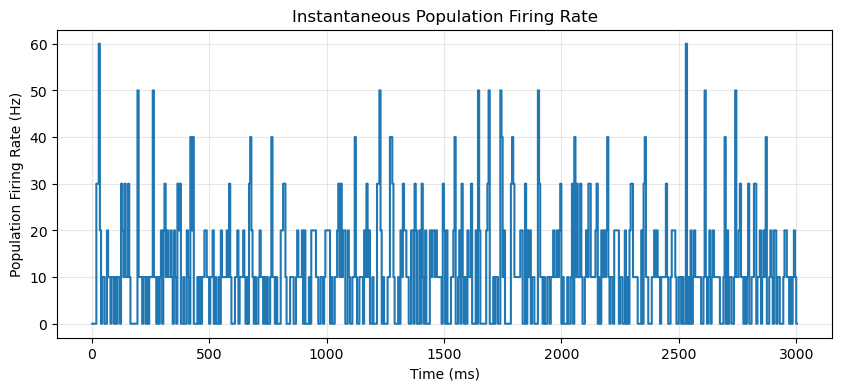

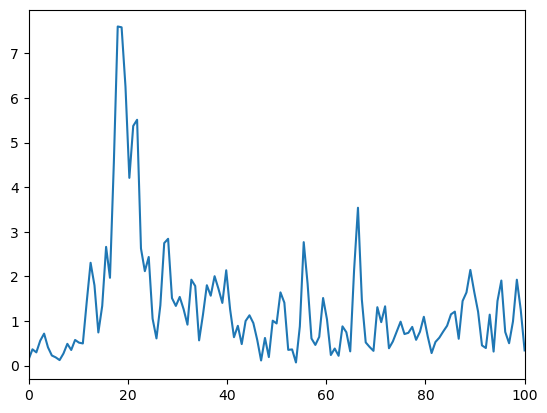

In [14]:

def calculate_instantaneous_rate(spikeTimes, runTime, binsize):
    nNeurons = len(spikeTimes)
    all_spikes = np.concatenate(spikeTimes)
    bin_edges = np.arange(0, runTime + binsize, binsize)
    counts, _ = np.histogram(all_spikes, bins=bin_edges)
    rate_vector = 1e3* counts / (nNeurons * binsize)
    bin_centers = bin_edges[:-1] + (binsize / 2)

    return rate_vector, bin_centers


def plotInstRate(spikeTimes,binsize = 5.0):
     # Using 10ms for a clearer rate plot example
    # Setting runTime slightly larger than the maximum spike time to cover the full range
    max_spike_time = np.max(np.concatenate(spikeTimes))
    runTime = np.ceil(max_spike_time / binsize) * binsize + binsize # e.g., ~380ms

    # Calculate the rate
    population_rate, time_vector = calculate_instantaneous_rate(spikeTimes, runTime, binsize)

    plt.figure(figsize=(10, 4))
    plt.plot(time_vector, population_rate, linestyle='-', drawstyle='steps-mid')
    plt.title('Instantaneous Population Firing Rate')
    plt.xlabel('Time (ms)')
    plt.ylabel('Population Firing Rate (Hz)')
    plt.grid(True, alpha=0.3)
    plt.show()

    plt.figure()
    f,pxx = welch(population_rate,fs=1000/binsize)
    plt.plot(f,pxx)
    plt.xlim(0,100)
    
spikeTimes = spikeTimeDict["STN"]
plotInstRate(spikeTimes)